# 🌿 EcoCore — Live Predictive Decision Dashboard

**Explainable predictive decision support for IBM LinuxONE / IBM Z critical workloads**

This notebook is designed for a live demonstration. It refreshes automatically and shows the current host metrics, an understandable explanation, projected next-horizon outcomes for three hypothetical actions, a reasoned recommendation, and safety steps.

### Important data-source rule
- **Live host telemetry** reads the host visible to this Jupyter kernel through `psutil`. It is genuine live data from that runtime, but it is LinuxONE telemetry only if this kernel is running on the LinuxONE host (or the telemetry collector has been connected to it).
- **Synthetic judge demo** generates labelled demo values to reliably demonstrate changing trends and decisions. It is *not* real server telemetry.
- EcoCore is **read-only**. The notebook does not pause, kill, migrate, or otherwise modify workloads.
- The Random Forest is trained on **synthetic future-pressure labels**. The displayed hybrid pressure score is not a calibrated outage probability.

### Quick start
1. Run all cells from top to bottom.
2. The dashboard starts auto-refreshing. Use **Live host telemetry** when the kernel is on LinuxONE; use **Synthetic judge demo** for a repeatable judging demonstration.
3. To stop refresh, click **Stop auto-refresh**. A kernel restart also stops the notebook task.


**Server integration:** LIVE mode reads `telemetry.collect_metrics()` and the existing `predictor_accurate.py` (preferred) or `predictor.py` module from the Jupyter server's Python path. It fails clearly if these are missing instead of fabricating live readings or silently training a replacement model.


In [1]:
%pip install -q psutil pandas numpy scikit-learn matplotlib


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
import math
import time
import asyncio
import platform
from datetime import datetime
from collections import deque

import numpy as np
import pandas as pd
import psutil
import matplotlib.pyplot as plt
from IPython.display import display, clear_output, HTML, Markdown
import io
import base64
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Prime non-blocking psutil CPU sampling so the first displayed sample is not always zero.
try:
    psutil.cpu_percent(interval=None)
except Exception:
    pass

print('EcoCore dependencies loaded.')
print('Kernel OS:', platform.platform())
print('Kernel architecture:', platform.machine())
if platform.machine().lower() not in ('s390x', 's390'):
    print('NOTICE: this kernel is not reporting s390x. Live mode will measure this kernel host, not confirm LinuxONE telemetry.')

# Disable nested, fixed-height notebook output scrolling for the dashboard output.
# The page can scroll normally; all dashboard sections remain in one continuous output.
_display_layout_css = r"""
<style>
.jp-Cell.jp-mod-outputsScrolled .jp-OutputArea-child,
.jp-Cell.jp-mod-outputsScrolled .jp-OutputArea-output,
.jp-Cell.jp-mod-outputsScrolled .jp-OutputArea,
.jp-Cell-outputWrapper .output_scroll,
div.output_scroll {
  max-height: none !important;
  height: auto !important;
  overflow: visible !important;
}
.jp-Cell.jp-mod-outputsScrolled .jp-OutputArea-child {
  min-height: 0 !important;
}
</style>
"""
display(HTML(_display_layout_css))


EcoCore dependencies loaded.
Kernel OS: Linux-6.8.0-147-generic-s390x-with-glibc2.39
Kernel architecture: s390x


In [3]:
# Use the existing project model on the LinuxONE server. Do NOT train a replacement model here.
# Supported module names from the project files: predictor_accurate.py or predictor.py.
import importlib
import pandas as pd
import numpy as np

FEATURES = ['cpu_pct', 'memory_pct', 'load_per_core', 'cpu_trend', 'memory_trend']

try:
    import predictor_accurate as _predictor_module
    importlib.reload(_predictor_module)
    predict = _predictor_module.predict
    GLOBAL_IMPORTANCE = getattr(_predictor_module, 'GLOBAL_IMPORTANCE', None)
    MODEL_SOURCE = 'predictor_accurate.py (server project model)'
except ImportError:
    try:
        import predictor as _predictor_module
        importlib.reload(_predictor_module)
        predict = _predictor_module.predict
        GLOBAL_IMPORTANCE = getattr(_predictor_module, 'GLOBAL_IMPORTANCE', None)
        MODEL_SOURCE = 'predictor.py (server project model)'
    except ImportError as exc:
        raise ImportError(
            "Could not find predictor_accurate.py or predictor.py in the Jupyter working directory. "
            "Put your existing server model module in that folder; this dashboard intentionally "
            "does not silently train a replacement model."
        ) from exc

if GLOBAL_IMPORTANCE is None:
    _model = getattr(_predictor_module, 'model', None)
    _features = getattr(_predictor_module, 'FEATURES', FEATURES)
    if _model is not None and hasattr(_model, 'feature_importances_'):
        GLOBAL_IMPORTANCE = pd.Series(_model.feature_importances_, index=_features).sort_values(ascending=False)
    else:
        GLOBAL_IMPORTANCE = pd.Series(dtype=float)

def model_pressure_probability(metrics):
    result = predict(dict(metrics))
    if not isinstance(result, dict) or 'risk_probability' not in result:
        raise ValueError("The server predictor must return {'risk_probability': float, ...}.")
    probability = float(result['risk_probability'])
    if not np.isfinite(probability) or not 0.0 <= probability <= 1.0:
        raise ValueError(f"Invalid risk_probability from server predictor: {probability}")
    return probability

display(HTML(
    '<h3>Existing server prediction model loaded</h3>'
    f'<p><b>Model source:</b> {MODEL_SOURCE}. '
    'The dashboard uses the model module already installed on the server; '
    'it does not train a new model in this notebook.</p>'
))
if len(GLOBAL_IMPORTANCE):
    display(GLOBAL_IMPORTANCE.rename('Global feature importance').to_frame())


,Global feature importance
cpu_pct,0.380061
memory_pct,0.375428
cpu_trend,0.118165
load_per_core,0.082556
memory_trend,0.043789


In [4]:
# Read live metrics from the existing server telemetry module (Member 1 interface).
# The expected interface is: from telemetry import collect_metrics; collect_metrics() -> dict.
try:
    import telemetry
    importlib.reload(telemetry)
    _server_collect_metrics = telemetry.collect_metrics
except ImportError as exc:
    raise ImportError(
        "Could not find telemetry.py in the Jupyter working directory. "
        "Copy/use the telemetry.py already present on your LinuxONE server, "
        "or add its directory to sys.path. This dashboard will not substitute "
        "synthetic values in LIVE mode."
    ) from exc

def collect_live_metrics():
    raw = dict(_server_collect_metrics())
    required = ['cpu_pct', 'memory_pct', 'load_per_core', 'process_count', 'logical_cores']
    missing = [key for key in required if key not in raw]
    if missing:
        raise KeyError(
            "telemetry.collect_metrics() is missing required keys: "
            + ', '.join(missing)
        )
    raw.setdefault('timestamp', datetime.now().astimezone().isoformat(timespec='seconds'))
    raw.setdefault('data_source', 'LIVE SERVER TELEMETRY MODULE')
    raw.setdefault('load_source', 'telemetry.collect_metrics()')
    raw['cpu_pct'] = float(raw['cpu_pct'])
    raw['memory_pct'] = float(raw['memory_pct'])
    raw['load_per_core'] = float(raw['load_per_core'])
    raw['process_count'] = int(raw['process_count'])
    raw['logical_cores'] = int(raw['logical_cores'])
    raw['data_source'] = 'LIVE SERVER TELEMETRY MODULE'
    return raw


# Synthetic scenario generator. Every generated value is explicitly marked DEMO/SYNTHETIC.
def collect_demo_metrics(preset, tick):
    t = int(tick)
    if preset == 'Normal workload':
        cpu = 30 + 2.0 * math.sin(t * 0.50)
        memory = 48 + 0.7 * math.sin(t * 0.19)
        load = 0.30 + 0.025 * math.sin(t * 0.43)
        processes = 95 + (t % 5)
    elif preset == 'Rising CPU pressure':
        cpu = min(69 + 0.72 * t, 89) + 1.2 * math.sin(t * 0.60)
        memory = min(67 + 0.22 * t, 79) + 0.5 * math.sin(t * 0.25)
        load = min(0.78 + 0.018 * t, 1.18) + 0.025 * math.sin(t * 0.40)
        processes = 150 + (t % 9)
    elif preset == 'Memory pressure':
        cpu = 43 + 1.7 * math.sin(t * 0.30)
        memory = min(77 + 0.43 * t, 94) + 0.55 * math.sin(t * 0.22)
        load = 0.66 + 0.02 * math.sin(t * 0.36)
        processes = 175 + (t % 7)
    else:  # Critical CPU + memory pressure
        cpu = min(94 + 0.12 * t, 99.0) + 0.35 * math.sin(t * 0.50)
        memory = min(88 + 0.12 * t, 95.0) + 0.25 * math.sin(t * 0.30)
        load = min(1.48 + 0.006 * t, 1.8) + 0.025 * math.sin(t * 0.40)
        processes = 330 + (t % 11)
    return {
        'timestamp': datetime.now().astimezone().isoformat(timespec='seconds'),
        'cpu_pct': float(np.clip(cpu, 0, 100)),
        'memory_pct': float(np.clip(memory, 0, 100)),
        'load_per_core': float(np.clip(load, 0, 10)),
        'process_count': int(processes),
        'logical_cores': 8,
        'data_source': 'SYNTHETIC DEMO — NOT LINUXONE TELEMETRY',
        'load_source': 'synthetic scenario assumption',
    }


def add_trends(metrics, previous):
    m = dict(metrics)
    if previous is None:
        m['cpu_trend'] = 0.0
        m['memory_trend'] = 0.0
    else:
        # Change in percentage points per refresh sample, not per second.
        m['cpu_trend'] = float(m['cpu_pct'] - previous['cpu_pct'])
        m['memory_trend'] = float(m['memory_pct'] - previous['memory_pct'])
    return m


# Hybrid pressure score: maximum of synthetic-trained model output and a transparent threshold guardrail.
# It is a demo/operational pressure index, NOT a calibrated probability of outage.
def guardrail_pressure_score(metrics, cpu_trend=None, memory_trend=None):
    cpu = float(metrics['cpu_pct'])
    memory = float(metrics['memory_pct'])
    load = float(metrics['load_per_core'])
    cpu_trend = float(metrics.get('cpu_trend', 0.0) if cpu_trend is None else cpu_trend)
    memory_trend = float(metrics.get('memory_trend', 0.0) if memory_trend is None else memory_trend)
    pressure_ratio = max(cpu / 80.0, memory / 85.0, load / 1.20)
    logit = (pressure_ratio - 1.0) * 10.0
    logit += max(cpu_trend, 0.0) * 0.025
    logit += max(memory_trend, 0.0) * 0.015
    logit = max(-30.0, min(30.0, logit))
    return 1.0 / (1.0 + math.exp(-logit))


def pressure_score(metrics, cpu_trend=None, memory_trend=None):
    m = dict(metrics)
    if cpu_trend is not None:
        m['cpu_trend'] = float(cpu_trend)
    if memory_trend is not None:
        m['memory_trend'] = float(memory_trend)
    ml_score = model_pressure_probability(m)
    guardrail = guardrail_pressure_score(m)
    return {
        'pressure_score': max(ml_score, guardrail),
        'model_score': ml_score,
        'guardrail_score': guardrail,
        'risk_level': 'HIGH' if max(ml_score, guardrail) >= 0.70 else 'ELEVATED' if max(ml_score, guardrail) >= 0.40 else 'LOW',
    }


def explain_current(metrics, current_score, no_action_projection, no_action_score):
    cpu, mem, load = metrics['cpu_pct'], metrics['memory_pct'], metrics['load_per_core']
    ct, mt = metrics.get('cpu_trend', 0.0), metrics.get('memory_trend', 0.0)
    drivers = [
        ('CPU', cpu / 80.0, f'CPU is {cpu:.1f}% (guardrail 80%).'),
        ('Memory', mem / 85.0, f'Memory is {mem:.1f}% (guardrail 85%).'),
        ('Load per core', load / 1.20, f'Load per core is {load:.2f} (guardrail 1.20).'),
    ]
    strongest = max(drivers, key=lambda item: item[1])
    items = [f"Current pressure is {current_score['risk_level']} at {current_score['pressure_score']:.1%} on EcoCore's hybrid pressure scale."]
    if strongest[1] >= 0.80:
        items.append(f"Main resource driver: {strongest[2]}")
    else:
        items.append(f"No single resource is close to its guardrail. Highest relative driver: {strongest[0]} ({strongest[1]:.0%} of its guardrail).")
    if ct >= 0.5:
        items.append(f'CPU is trending upward by {ct:+.2f} percentage points per sample.')
    elif ct <= -0.5:
        items.append(f'CPU is trending downward by {ct:+.2f} percentage points per sample.')
    else:
        items.append(f'CPU trend is currently stable ({ct:+.2f} percentage points per sample).')
    if mt >= 0.3:
        items.append(f'Memory is trending upward by {mt:+.2f} percentage points per sample.')
    elif mt <= -0.3:
        items.append(f'Memory is trending downward by {mt:+.2f} percentage points per sample.')
    if no_action_projection['cpu_pct'] >= 80 and cpu < 80:
        items.append(f"If no action is taken, the CPU projection reaches {no_action_projection['cpu_pct']:.1f}% over the selected horizon, above the 80% guardrail.")
    if no_action_projection['memory_pct'] >= 85 and mem < 85:
        items.append(f"If no action is taken, the memory projection reaches {no_action_projection['memory_pct']:.1f}% over the selected horizon, above the 85% guardrail.")
    if no_action_score['pressure_score'] > current_score['pressure_score'] + 0.08:
        items.append('The no-action projection increases the pressure score materially; review the available workload-safe options below.')
    elif current_score['pressure_score'] < 0.40:
        items.append('Current and projected pressure are relatively low; continued monitoring may be safer than unnecessary intervention.')
    return items


def simulate_scenarios(metrics, horizon_samples, allow_defer, capacity_ok, compatibility_ok,
                       defer_cpu_relief=15.0, defer_memory_relief=5.0,
                       redistribute_cpu_relief=10.0, redistribute_memory_overhead=2.0):
    cpu = float(metrics['cpu_pct'])
    mem = float(metrics['memory_pct'])
    load = float(metrics['load_per_core'])
    cpu_trend = float(metrics.get('cpu_trend', 0.0))
    memory_trend = float(metrics.get('memory_trend', 0.0))
    h = int(horizon_samples)
    actions = [
        {'action': 'No action', 'dcpu': 0.0, 'dmem': 0.0, 'trend_scale': 1.0, 'penalty': 0.00,
         'available': True, 'assumption': 'Continue current workload; trend continues unchanged.'},
        {'action': 'Defer background workload', 'dcpu': -defer_cpu_relief, 'dmem': -defer_memory_relief,
         'trend_scale': 0.45, 'penalty': 0.04, 'available': bool(allow_defer),
         'assumption': f'Assumes only explicitly approved non-critical work can be deferred; relief assumed: CPU −{defer_cpu_relief:.0f} pp, memory −{defer_memory_relief:.0f} pp.'},
        {'action': 'Redistribute workload', 'dcpu': -redistribute_cpu_relief, 'dmem': redistribute_memory_overhead,
         'trend_scale': 0.60, 'penalty': 0.06, 'available': bool(capacity_ok and compatibility_ok),
         'assumption': f'Assumes a compatible destination with confirmed spare capacity; CPU relief −{redistribute_cpu_relief:.0f} pp and memory overhead +{redistribute_memory_overhead:.0f} pp are hypothetical.'},
    ]
    rows = []
    for action in actions:
        projected_cpu = float(np.clip(cpu + cpu_trend * h * action['trend_scale'] + action['dcpu'], 0, 100))
        projected_mem = float(np.clip(mem + memory_trend * h * action['trend_scale'] + action['dmem'], 0, 100))
        projected_load = float(np.clip(load + max(cpu_trend, 0) * h * action['trend_scale'] * 0.0037 + action['dcpu'] * 0.007, 0, 3))
        projected_cpu_trend = cpu_trend * action['trend_scale']
        projected_mem_trend = memory_trend * action['trend_scale']
        projection = {**metrics, 'cpu_pct': projected_cpu, 'memory_pct': projected_mem,
                      'load_per_core': projected_load, 'cpu_trend': projected_cpu_trend,
                      'memory_trend': projected_mem_trend}
        scores = pressure_score(projection)
        rows.append({
            'action': action['action'],
            'available': action['available'],
            'estimated_risk': scores['pressure_score'],
            'model_score': scores['model_score'],
            'guardrail_score': scores['guardrail_score'],
            'projected_cpu_pct': projected_cpu,
            'projected_memory_pct': projected_mem,
            'projected_load_per_core': projected_load,
            'projected_cpu_trend': projected_cpu_trend,
            'projected_memory_trend': projected_mem_trend,
            'intervention_penalty': action['penalty'],
            'decision_score': scores['pressure_score'] + action['penalty'] if action['available'] else None,
            'risk_level': scores['risk_level'],
            'assumption': action['assumption'],
            'restriction': '' if action['available'] else (
                'Confirm safe-to-defer non-critical work before enabling.' if action['action'] == 'Defer background workload'
                else 'Requires confirmed compatible destination AND confirmed spare capacity.'
            ),
        })
    return rows


def recommend(scenarios):
    available = [r for r in scenarios if r['available'] and r['decision_score'] is not None]
    if not available:
        return {'action': 'Escalate / investigate', 'reason': 'No intervention beyond no-action was verified safe and available.'}
    best = min(available, key=lambda row: (row['decision_score'], row['intervention_penalty']))
    if best['estimated_risk'] >= 0.90:
        return {**best, 'action': 'Escalate / investigate', 'original_best_action': best['action'],
                'reason': 'Even the best currently available option leaves very high projected pressure (≥90%). Escalate to the operator/on-call runbook; do not blindly automate a change.'}
    reasons = {
        'No action': 'No-action has the lowest adjusted score among available options. Pressure is not improved enough by the assumed interventions to justify their added change risk; keep monitoring.',
        'Defer background workload': 'Deferring approved non-critical background work gives the lowest adjusted score among available options. Confirm the exact workload and owner/runbook approval before acting.',
        'Redistribute workload': 'Redistribution has the lowest adjusted score among the options marked available. This is only a recommendation: validate destination capacity, compatibility, I/O, network and latency/SLO headroom, and rollback before an approved change.',
    }
    return {**best, 'reason': reasons[best['action']]}


def safety_checklist(metrics, score, recommendation):
    action = recommendation['action']
    if action == 'Escalate / investigate' or score >= 0.90:
        return [
            'Escalate to the on-call operator and verify CPU, memory, load and workload latency in the native LinuxONE monitoring tools.',
            'Protect critical workloads and follow the incident/runbook process; do not kill processes or migrate work based on this prototype score alone.',
            'Only defer work whose non-critical status and owner approval are confirmed. Treat capacity/compatibility as unverified unless measured independently.',
            'If pressure continues to worsen, use the approved incident-response and capacity procedures; this dashboard does not execute recovery actions.',
        ]
    if score >= 0.70 or metrics['cpu_pct'] >= 90 or metrics['memory_pct'] >= 90 or metrics['load_per_core'] >= 1.5:
        return [
            'Validate the signal against native host/LPAR monitoring and application latency/SLOs before changing workload placement.',
            'Identify top CPU/memory consumers and protect critical services; defer only pre-identified non-critical background work with approval.',
            'Before redistribution, verify target compatibility, spare CPU and memory, I/O/network headroom, affinity constraints and a rollback plan.',
            'Keep a human in the approval loop. EcoCore only compares hypothetical options; it will not modify workloads.',
        ]
    if score >= 0.40:
        return [
            'Check which resource is driving the score and confirm the trend persists across more than one sample.',
            'Review queue depth, response latency and scheduled batch jobs; prepare a defer plan, but do not interrupt critical work blindly.',
            'Keep destination compatibility/capacity unverified until a trusted source confirms them; continue monitoring.',
        ]
    return [
        'Continue monitoring and retain the recent trend history; no intervention is indicated by this prototype score alone.',
        'Keep normal alerting and workload/SLO checks active. A low score is not a guarantee of service health.',
        'Do not change critical workloads solely because of a model output; all actions require the existing operator approval process.',
    ]


In [5]:
# Dashboard configuration — edit these values before running the live-refresh cell.
# LIVE reads the current kernel host. Use DEMO for clearly labelled synthetic judge scenarios.
DATA_MODE = 'DEMO'  # 'LIVE' or 'DEMO'
DEMO_PRESET = 'Rising CPU pressure'  # Normal workload / Rising CPU pressure / Memory pressure / Critical CPU + memory pressure / CYCLE
REFRESH_SECONDS = 2
HORIZON_SAMPLES = 4

# Safety gates: keep False unless verified independently. Deferral is only a what-if unless approved.
ALLOW_DEFER = False
DESTINATION_CAPACITY_CONFIRMED = False
DESTINATION_COMPATIBLE = False

HISTORY_LIMIT = 60
DEMO_CYCLE_EVERY = 8  # if DEMO_PRESET='CYCLE', switch scenario every N refreshes

assert DATA_MODE.upper() in {'LIVE', 'DEMO'}
assert 1 <= int(HORIZON_SAMPLES) <= 12
assert 1 <= int(REFRESH_SECONDS) <= 60
print('Configuration ready:', DATA_MODE, '| refresh:', REFRESH_SECONDS, 'seconds | horizon:', HORIZON_SAMPLES, 'samples')


Configuration ready: DEMO | refresh: 2 seconds | horizon: 4 samples


## Judge presentation guide

### Recommended way to present it
1. **For true live data:** leave `DATA_MODE = 'LIVE'` and run the dashboard only when the notebook kernel is on LinuxONE (architecture `s390x`/`s390`) or the telemetry collector has been connected to that host. Point to the last-sample timestamp and recent chart.
2. **For a repeatable demonstration on a laptop:** stop the loop, set `DATA_MODE = 'DEMO'` and `DEMO_PRESET = 'CYCLE'` in the configuration cell, then rerun the dashboard cell. It cycles labelled synthetic cases (normal, rising CPU, memory pressure and critical pressure); no synthetic value is represented as live hardware.
3. To demonstrate the defer option, set `ALLOW_DEFER = True` only for a demo or after a responsible operator has confirmed that suitable non-critical background work exists. For redistribution, **both** destination checkboxes/config values must be independently verified as true. Otherwise the action stays unavailable.
4. Explain that “No action” can be correct at low pressure. Under critical conditions the engine recommends **Escalate / investigate** when even the best available action leaves very high projected pressure.

### Safety boundary
EcoCore only recommends. It does not kill, pause, defer, or migrate a workload. Before any real action, verify metrics using native LinuxONE / LPAR monitoring, preserve critical workload priorities, confirm job criticality and owner approval, and for redistribution validate destination compatibility, CPU/memory headroom, I/O and network capacity, latency/SLOs, and rollback.

### Limitations that should be disclosed to judges
- The uploaded project did not include a remote telemetry endpoint, credentials, or agent configuration. Therefore, this notebook reads the kernel host in live mode; it cannot establish a remote LinuxONE connection by guessing.
- The Random Forest model is trained and evaluated on synthetic data. The displayed score is a hybrid pressure index, not a calibrated probability of outage.
- Scenario relief values and intervention penalties are what-if assumptions and must be tuned against representative workload measurements before operational use.


EcoCore dashboard started. One display is updated in place to prevent flicker and stacked outputs.
Stop refresh with Kernel → Interrupt.


What-if action,Availability,Projected CPU,Projected memory,Projected load/core,Pressure score,Decision score,Assumption / restriction
No action,AVAILABLE,85.6%,79.7%,1.155,66.9%,0.669,Continue current workload; trend continues unchanged.
Defer background workload,UNAVAILABLE,72.1%,74.5%,1.050,27.0%,—,Confirm safe-to-defer non-critical work before enabling.
Redistribute workload,UNAVAILABLE,76.7%,81.5%,1.085,48.0%,—,Requires confirmed compatible destination AND confirmed spare capacity.

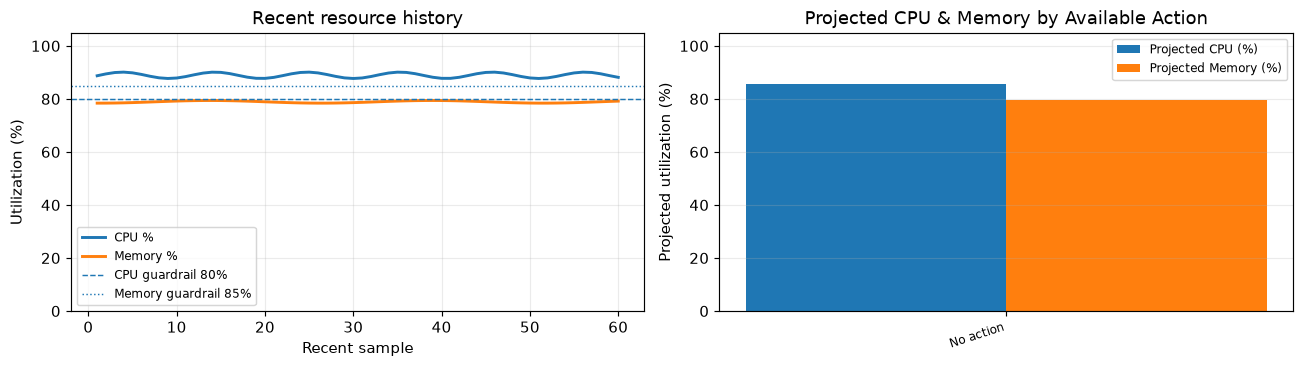

In [ ]:
from IPython.display import clear_output

history = deque(maxlen=max(5, int(HISTORY_LIMIT)))
previous_metrics = None
refresh_count = 0
DEMO_PRESETS = ['Normal workload', 'Rising CPU pressure', 'Memory pressure', 'Critical CPU + memory pressure']


def current_sample():
    global previous_metrics, refresh_count
    mode = DATA_MODE.upper()
    if mode == 'LIVE':
        raw = collect_live_metrics()
        label = 'LIVE SERVER TELEMETRY MODULE'
    elif mode == 'DEMO':
        if DEMO_PRESET.upper() == 'CYCLE':
            preset = DEMO_PRESETS[(refresh_count // max(1, int(DEMO_CYCLE_EVERY))) % len(DEMO_PRESETS)]
        else:
            preset = DEMO_PRESET
        if preset not in DEMO_PRESETS:
            raise ValueError(f'DEMO_PRESET must be one of {DEMO_PRESETS} or CYCLE')
        raw = collect_demo_metrics(preset, refresh_count)
        raw['demo_preset'] = preset
        label = 'SYNTHETIC DEMO — NOT LINUXONE TELEMETRY'
    else:
        raise ValueError("DATA_MODE must be 'LIVE' or 'DEMO'")
    m = add_trends(raw, previous_metrics)
    m['source_label'] = label
    previous_metrics = dict(m)
    refresh_count += 1
    return m


def safe_html(text):
    import html
    return html.escape(str(text))


def render_dashboard_once():
    m = current_sample()
    current = pressure_score(m)
    h = int(HORIZON_SAMPLES)
    no_action_projection = {
        'cpu_pct': float(np.clip(m['cpu_pct'] + m['cpu_trend'] * h, 0, 100)),
        'memory_pct': float(np.clip(m['memory_pct'] + m['memory_trend'] * h, 0, 100)),
        'load_per_core': float(np.clip(m['load_per_core'] + max(m['cpu_trend'], 0) * h * 0.0037, 0, 3)),
    }
    no_action_metrics = {**m, **no_action_projection,
                         'cpu_trend': m['cpu_trend'], 'memory_trend': m['memory_trend']}
    no_action_score = pressure_score(no_action_metrics)
    scenarios = simulate_scenarios(
        m, horizon_samples=h,
        allow_defer=bool(ALLOW_DEFER),
        capacity_ok=bool(DESTINATION_CAPACITY_CONFIRMED),
        compatibility_ok=bool(DESTINATION_COMPATIBLE),
    )
    rec = recommend(scenarios)
    explanations = explain_current(m, current, no_action_projection, no_action_score)
    safety_items = safety_checklist(m, current['pressure_score'], rec)
    history.append({
        'time': m['timestamp'], 'cpu': m['cpu_pct'], 'memory': m['memory_pct'],
        'load': m['load_per_core'], 'processes': m['process_count'],
        'pressure': current['pressure_score'] * 100,
    })
    hist = pd.DataFrame(list(history))

    arch = platform.machine().lower()
    is_s390x = arch in ('s390x', 's390')
    if m['source_label'].startswith('SYNTHETIC'):
        banner_color = '#92400e'
        source_note = '<b>DEMO / SYNTHETIC DATA.</b> Generated scenario readings; these are not actual LinuxONE telemetry.'
        demo_detail = f" Scenario preset: <b>{safe_html(m.get('demo_preset', ''))}</b>."
    elif not is_s390x:
        banner_color = '#9f1239'
        source_note = '<b>HOST WARNING.</b> This kernel is not reporting s390x. Live values are from the machine/container running Jupyter and are not confirmed as physical LinuxONE readings.'
        demo_detail = ''
    else:
        banner_color = '#166534'
        source_note = '<b>LIVE SERVER TELEMETRY.</b> Values are collected by the existing telemetry.collect_metrics() module on this server.'
        demo_detail = ''

    score = current['pressure_score']
    score_color = '#166534' if score < 0.40 else '#a16207' if score < 0.70 else '#b91c1c'
    cards = [
        ('CPU', f"{m['cpu_pct']:.1f}%", f"trend {m['cpu_trend']:+.2f} pp/sample"),
        ('Memory', f"{m['memory_pct']:.1f}%", f"trend {m['memory_trend']:+.2f} pp/sample"),
        ('Load / core', f"{m['load_per_core']:.3f}", 'guardrail 1.20'),
        ('Processes', f"{m['process_count']:,}", f"{m['logical_cores']} logical cores"),
        ('Pressure score', f"{score:.1%}", current['risk_level']),
    ]
    cards_html = ''.join(
        "<div class='ec-card'><div class='ec-label'>" + label + "</div><div class='ec-value' style='color:" + (score_color if label == 'Pressure score' else '#172033') + "'>" + value + "</div><div class='ec-sub'>" + sub + "</div></div>"
        for label, value, sub in cards
    )
    banner = f"<div style='padding:10px 12px;border-left:5px solid {banner_color};background:#f8fafc;border-radius:8px;margin:8px 0 14px 0'>{source_note}{demo_detail}<br><small>Architecture: {safe_html(platform.machine())} · Last sample: {safe_html(m['timestamp'])} · Refresh target: {REFRESH_SECONDS}s</small></div>"
    explanation_html = '<ol>' + ''.join(f'<li>{safe_html(item)}</li>' for item in explanations) + '</ol>'
    feature_names = ', '.join(x.replace('_', ' ').title() for x in GLOBAL_IMPORTANCE.sort_values(ascending=False).head(3).index)
    model_html = (f"<p><b>Random Forest estimate:</b> {current['model_score']:.1%} · <b>Resource guardrail:</b> {current['guardrail_score']:.1%} · <b>Global top features:</b> {safe_html(feature_names)}</p>"
                  "<p style='color:#5b6472;font-size:0.92em'>The hybrid pressure score is the higher of the model estimate and the transparent resource-pressure guardrail. It is not a calibrated outage probability. Feature importance is global, not a causal explanation for this one sample.</p>")

    scenario_records=[]
    for s in scenarios:
        scenario_records.append({
            'What-if action': s['action'],
            'Availability': 'AVAILABLE' if s['available'] else 'UNAVAILABLE',
            'Projected CPU': f"{s['projected_cpu_pct']:.1f}%",
            'Projected memory': f"{s['projected_memory_pct']:.1f}%",
            'Projected load/core': f"{s['projected_load_per_core']:.3f}",
            'Pressure score': f"{s['estimated_risk']:.1%}",
            'Decision score': '—' if s['decision_score'] is None else f"{s['decision_score']:.3f}",
            'Assumption / restriction': s['assumption'] if s['available'] else s['restriction'],
        })
    scenario_html = pd.DataFrame(scenario_records).to_html(index=False, escape=True, border=0, classes='ec-table')

    rec_color = '#166534' if rec['action'] == 'No action' else '#a16207' if rec['action'] == 'Defer background workload' else '#1d4ed8' if rec['action'] == 'Redistribute workload' else '#b91c1c'
    rec_pressure = f"{rec['estimated_risk']:.1%}" if 'estimated_risk' in rec else 'No verified low-risk choice'
    rec_html = (f"<div style='border:1px solid #d7dde6;border-left:6px solid {rec_color};border-radius:10px;padding:14px;margin:8px 0'>"
                f"<div style='font-size:12px;color:#536174;text-transform:uppercase;letter-spacing:.06em'>Recommended next move</div>"
                f"<div style='font-size:24px;font-weight:750;color:{rec_color};margin:4px 0'>{safe_html(rec['action'])}</div>"
                f"<div><b>Projected pressure:</b> {rec_pressure}</div><p>{safe_html(rec.get('reason','Review scenario eligibility and safety checks.'))}</p>"
                "<p style='font-size:.92em;color:#5b6472'>Decision score = projected pressure score + intervention penalty. Lower is preferred; unavailable actions are never selected.</p></div>")
    safety_html = '<ol>' + ''.join(f'<li>{safe_html(item)}</li>' for item in safety_items) + '</ol>'
    live_host_warning = "" if (DATA_MODE.upper() == 'DEMO' or is_s390x) else "<p style='color:#9f1239'><b>Before calling this LinuxONE telemetry:</b> run the kernel on LinuxONE or connect a secure telemetry agent/API. This notebook cannot infer or create a remote connection.</p>"

    dashboard_html = f"""
    <style>
    .ec-wrap{{font-family:Arial,sans-serif;color:#172033}}
    .ec-cards{{display:grid;grid-template-columns:repeat(5,minmax(110px,1fr));gap:10px;margin:12px 0}}
    .ec-card{{background:#f8fafc;border:1px solid #e2e8f0;border-radius:10px;padding:12px}}
    .ec-label{{color:#5b6472;font-size:12px;margin-bottom:5px}}
    .ec-value{{font-size:25px;font-weight:750;line-height:1.15}}
    .ec-sub{{color:#64748b;font-size:12px;margin-top:5px}}
    .ec-table{{border-collapse:collapse;width:100%;font-size:13px;margin:6px 0 12px 0}}
    .ec-table th{{text-align:left;background:#eef2f7;padding:8px;border-bottom:1px solid #cbd5e1}}
    .ec-table td{{padding:8px;border-bottom:1px solid #e2e8f0;vertical-align:top}}
    .ec-table tr:nth-child(even){{background:#fafbfc}}
    @media(max-width:800px){{.ec-cards{{grid-template-columns:repeat(2,minmax(110px,1fr))}}}}
    </style>
    <div class='ec-wrap'>
    <h2 style='margin-bottom:2px'>🌿 EcoCore · Live Predictive Decision Dashboard</h2>
    <div style='color:#64748b;margin-bottom:8px'>Current telemetry → plain-language explanation → next-horizon scenarios → recommendation → safety checklist</div>
    {banner}{live_host_warning}
    <div class='ec-cards'>{cards_html}</div>
    <h3>1 · Real-time explanation — why this score?</h3>{explanation_html}{model_html}
    <h3>2 · What-if decision engine — predicted next-horizon outcomes</h3>
    <p>Forecast horizon: <b>{h} refresh samples</b> (roughly {h * REFRESH_SECONDS} seconds at the selected refresh target). Trend projection, relief amounts, and intervention penalties are assumptions—not measured intervention results. No workload action is executed.</p>
    </div>
    """
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
    axes[0].plot(range(1, len(hist) + 1), hist['cpu'], label='CPU %', linewidth=2)
    axes[0].plot(range(1, len(hist) + 1), hist['memory'], label='Memory %', linewidth=2)
    axes[0].axhline(80, linestyle='--', linewidth=1, label='CPU guardrail 80%')
    axes[0].axhline(85, linestyle=':', linewidth=1, label='Memory guardrail 85%')
    axes[0].set_title('Recent resource history')
    axes[0].set_xlabel('Recent sample'); axes[0].set_ylabel('Utilization (%)')
    axes[0].set_ylim(0, 105); axes[0].grid(alpha=0.25); axes[0].legend(fontsize=8)
    # Compare projected CPU and memory for every scenario marked available.
    # Unavailable actions remain visible in the scenario table with their restriction reason.
    available_rows = [s for s in scenarios if s.get('available', False)]
    x = np.arange(len(available_rows))
    width = 0.35

    if available_rows:
        axes[1].bar(
            x - width / 2,
            [float(s['projected_cpu_pct']) for s in available_rows],
            width,
            label='Projected CPU (%)'
        )
        axes[1].bar(
            x + width / 2,
            [float(s['projected_memory_pct']) for s in available_rows],
            width,
            label='Projected Memory (%)'
        )
        axes[1].set_xticks(x)
        axes[1].set_xticklabels(
            [s['action'] for s in available_rows],
            rotation=18,
            ha='right',
            fontsize=8
        )
        axes[1].legend(fontsize=8)
    else:
        axes[1].text(0.5, 0.5, 'No available scenarios', ha='center', va='center', transform=axes[1].transAxes)

    axes[1].set_title('Projected CPU & Memory by Available Action')
    axes[1].set_ylabel('Projected utilization (%)')
    axes[1].set_ylim(0, 105)
    axes[1].grid(axis='y', alpha=0.25)
    fig.tight_layout()
    chart_buffer = io.BytesIO()
    fig.savefig(chart_buffer, format='png', dpi=105, bbox_inches='tight')
    plt.close(fig)
    chart_b64 = base64.b64encode(chart_buffer.getvalue()).decode('ascii')
    chart_html = ("<img alt='Recent resource history and projected pressure chart' "
                  "style='display:block;width:100%;max-width:1350px;height:auto;margin:8px 0 14px 0' "
                  f"src='data:image/png;base64,{chart_b64}' />")

    complete_html = dashboard_html + f"""
    <div class='ec-wrap'>
      <div class='ec-table-wrap' style='overflow-x:auto;width:100%'>
        {scenario_html}
      </div>
      {chart_html}
      <h3>3 · Recommendation — what should happen next?</h3>{rec_html}
      <h3>4 · Safety actions to reduce service-impact risk</h3>{safety_html}
      <p style='background:#f8fafc;border:1px solid #e2e8f0;border-radius:8px;padding:10px'>
        <b>Safety boundary:</b> read-only decision support. No automatic workload modification. 
        Verify production decisions with native host monitoring and your runbook.
      </p>
    </div>
    """
    # Jupyter output area CSS: let the notebook page scroll instead of trapping the dashboard
    # inside a small nested scrolling pane. This is repeated in the refreshed output too.
    output_css = """<style>
      .jp-Cell.jp-mod-outputsScrolled .jp-OutputArea-child,
      .jp-Cell.jp-mod-outputsScrolled .jp-OutputArea-output,
      .jp-Cell.jp-mod-outputsScrolled .jp-OutputArea,
      .jp-Cell-outputWrapper .output_scroll, div.output_scroll {
        max-height:none !important; height:auto !important; overflow:visible !important;
      }
      .ec-wrap { max-width: 100%; box-sizing: border-box; }
      .ec-table-wrap { max-width: 100%; }
    </style>"""
    return output_css + complete_html


print('EcoCore dashboard started. One display is updated in place to prevent flicker and stacked outputs.')
print('Stop refresh with Kernel → Interrupt.')
dashboard_display = display(HTML("<div style='font-family:Arial;padding:12px'>Loading EcoCore telemetry and scenarios…</div>"), display_id=True)
try:
    while True:
        dashboard_html = render_dashboard_once()
        dashboard_display.update(HTML(dashboard_html))
        time.sleep(max(1, int(REFRESH_SECONDS)))
except KeyboardInterrupt:
    print('EcoCore dashboard stopped by user.')
